# NASA C-MAPSS FD001: predicting remaining useful life
Model: a small neural network (MLP) on the last 30 cycles of 14 sensors, RUL capped at 125. Evaluated with 5-fold cross-validation by engine, then once on NASA's test engines.

Run with **Runtime → Restart session and run all**. Every cell depends only on cells above it.

## 0. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import xgboost as xgb
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

# Folder with the data files. If they are on Google Drive, mount Drive and change this,
# for example to "/content/drive/MyDrive/cmapss/"
DATA = "/content/"

In [2]:
s = [f"s{i}" for i in range(1, 22)]
cols = ["unit", "cycle", "set1", "set2", "set3", *s]
cols

['unit',
 'cycle',
 'set1',
 'set2',
 'set3',
 's1',
 's2',
 's3',
 's4',
 's5',
 's6',
 's7',
 's8',
 's9',
 's10',
 's11',
 's12',
 's13',
 's14',
 's15',
 's16',
 's17',
 's18',
 's19',
 's20',
 's21']

## 1. Train data
100 engines, each run until it fails. No header in the file, so I named the 26 columns

In [3]:
df = pd.read_csv(DATA + "train_FD001.txt", header=None, sep=r"\s+", names=cols)
df.shape

(20631, 26)

In [4]:
df.head()

,unit,cycle,set1,set2,set3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   unit    20631 non-null  int64  
 1   cycle   20631 non-null  int64  
 2   set1    20631 non-null  float64
 3   set2    20631 non-null  float64
 4   set3    20631 non-null  float64
 5   s1      20631 non-null  float64
 6   s2      20631 non-null  float64
 7   s3      20631 non-null  float64
 8   s4      20631 non-null  float64
 9   s5      20631 non-null  float64
 10  s6      20631 non-null  float64
 11  s7      20631 non-null  float64
 12  s8      20631 non-null  float64
 13  s9      20631 non-null  float64
 14  s10     20631 non-null  float64
 15  s11     20631 non-null  float64
 16  s12     20631 non-null  float64
 17  s13     20631 non-null  float64
 18  s14     20631 non-null  float64
 19  s15     20631 non-null  float64
 20  s16     20631 non-null  float64
 21  s17     20631 non-null  int64  
 22

In [6]:
# duplicate check: every (engine, cycle) pair should appear once
train_dup = df.groupby(["unit", "cycle"]).size()
print("duplicate check:", train_dup.max())

duplicate check: 1


In [7]:
# life of each engine: first cycle, last cycle, number of rows
life = df.groupby("unit")["cycle"].agg(["min", "max", "count"])
print("all start at cycle 1:", (life["min"] == 1).all())
print("no gaps:", (life["count"] == life["max"]).all())
life["max"].describe()

all start at cycle 1: True
no gaps: True


,max
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000


In [8]:
# which columns never change
pd.DataFrame({
    "std": df[cols[2:]].std(),
    "nunique": df[cols[2:]].nunique(),
}).sort_values("nunique")

,std,nunique
s1,6.537152e-11,1
set3,0.000000e+00,1
s5,3.394700e-12,1
s10,4.660829e-13,1
s18,0.000000e+00,1
s19,0.000000e+00,1
s16,1.556432e-14,1
s6,1.388985e-03,2
s17,1.548763e+00,13
set2,2.930621e-04,13


## 2. Labels
- `failure_cycle`: the cycle on which the engine breaks
- `RUL` (remaining useful life): how many cycles are left until it breaks
- `cycles_left_capped`: RUL limited to 125. Far from failure the sensors look the same, so anything above 125 means "healthy, at least 125 left"

In [9]:
df["failure_cycle"] = df.groupby("unit")["cycle"].transform("max")
df["RUL"] = df["failure_cycle"] - df["cycle"]
df["cycles_left_capped"] = df["RUL"].clip(upper=125)
df[df["unit"] == 1][["unit", "cycle", "failure_cycle", "RUL", "cycles_left_capped"]].head(3)

,unit,cycle,failure_cycle,RUL,cycles_left_capped
0,1,1,192,191,125
1,1,2,192,190,125
2,1,3,192,189,125


In [10]:
# every engine's last row must be RUL = 0 (the failure)
print("all engines end at 0:", (df.groupby("unit")["RUL"].min() == 0).all())
print("max capped:", df["cycles_left_capped"].max())
print("rows changed by the cap:", (df["RUL"] > 125).sum())

all engines end at 0: True
max capped: 125
rows changed by the cap: 8031


## 3. Test data
100 different engines. NASA cut each one's data off **before** it failed.

In [11]:
test = pd.read_csv(DATA + "test_FD001.txt", header=None, sep=r"\s+", names=cols)
print(test.shape)
print(test["unit"].nunique())
test_dup = test.groupby(["unit", "cycle"]).size()
print("duplicate check:", test_dup.max())

(13096, 26)
100
duplicate check: 1


In [12]:
# how many cycles each test engine was observed for
test_life = test.groupby("unit")["cycle"].agg(["min", "max", "count"])
print("all start at cycle 1:", (test_life["min"] == 1).all())
print("no gaps:", (test_life["count"] == test_life["max"]).all())
test_life["max"].describe()

all start at cycle 1: True
no gaps: True


,max
count,100.000000
mean,130.960000
std,53.593479
min,31.000000
25%,88.750000
50%,133.500000
75%,164.250000
max,303.000000


In [13]:
pd.DataFrame({
    "std": test[cols[2:]].std(),
    "nunique": test[cols[2:]].nunique(),
}).sort_values("nunique")

,std,nunique
s1,6.014263e-11,1
set3,0.000000e+00,1
s5,2.671743e-12,1
s10,3.157595e-13,1
s18,0.000000e+00,1
s19,0.000000e+00,1
s16,8.823140e-15,1
s6,1.704085e-03,2
s17,1.233577e+00,9
set2,2.940306e-04,14


## 4. RUL file and sanity check
- One number per line: the RUL of each test engine at the point where NASA cut its data.
- No engine column: line 1 is engine 1, line 2 is engine 2. pandas counts rows from 0, so `unit = index + 1`.
- `nasa_cut_cycle`: the cycle where NASA cut the test data.

In [14]:
rul = pd.read_csv(DATA + "RUL_FD001.txt", header=None, sep=r"\s+", names=["RUL"])
rul["unit"] = rul.index + 1
rul["RUL"].describe()

,RUL
count,100.00000
mean,75.52000
std,41.76497
min,7.00000
25%,32.75000
50%,86.00000
75%,112.25000
max,145.00000


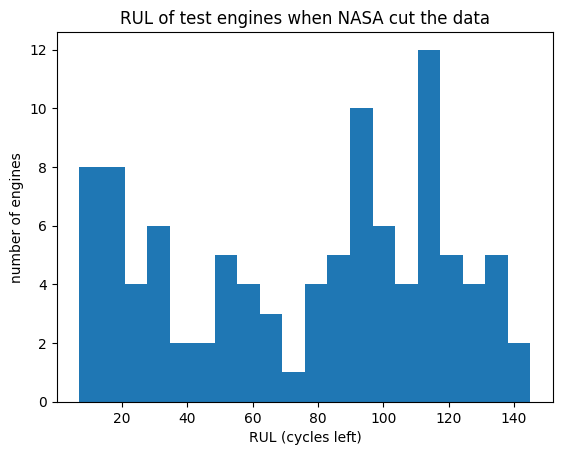

In [15]:
plt.hist(rul["RUL"], bins=20)
plt.title("RUL of test engines when NASA cut the data")
plt.xlabel("RUL (cycles left)")
plt.ylabel("number of engines")
plt.show()

In [16]:
cut = test.groupby("unit")["cycle"].max().rename("nasa_cut_cycle").reset_index()
check = rul.merge(cut, on="unit")
check["failure_cycle"] = check["nasa_cut_cycle"] + check["RUL"]
check.head()

,RUL,unit,nasa_cut_cycle,failure_cycle
0,112,1,31,143
1,98,2,49,147
2,69,3,126,195
3,82,4,106,188
4,91,5,98,189


In [17]:
# test engines' total lives should look like train engines' lives
pd.DataFrame({
    "train failure_cycle": life["max"].describe(),
    "test failure_cycle": check["failure_cycle"].describe(),
})

,train failure_cycle,test failure_cycle
count,100.000000,100.000000
mean,206.310000,206.480000
std,46.342749,44.041872
min,128.000000,141.000000
25%,177.000000,174.750000
50%,199.000000,199.000000
75%,229.250000,227.750000
max,362.000000,341.000000


## 5. Sensors over an engine's life

In [18]:
shortest = int(life["max"].idxmin())
longest = int(life["max"].idxmax())
engines = [shortest, 1, longest]
print("engines:", engines)

engines: [39, 1, 69]


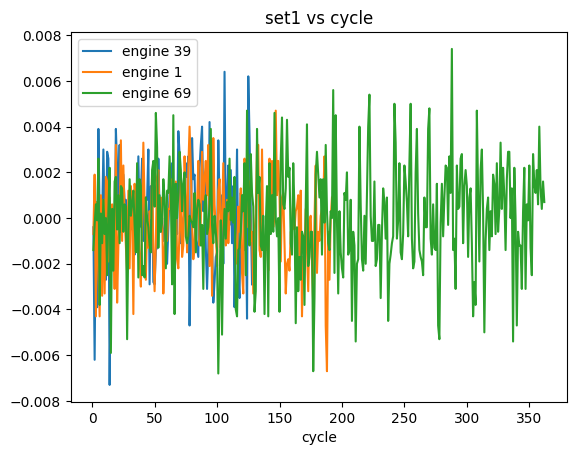

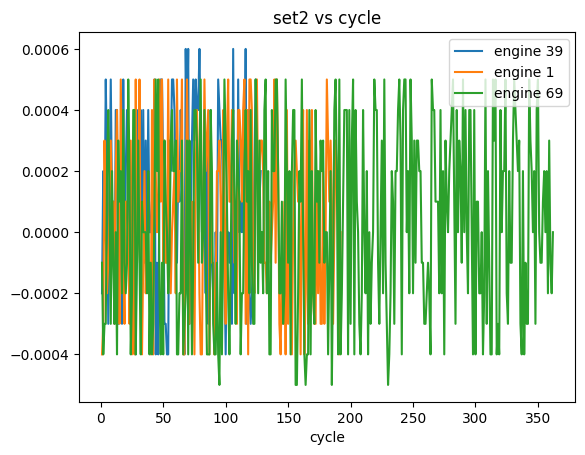

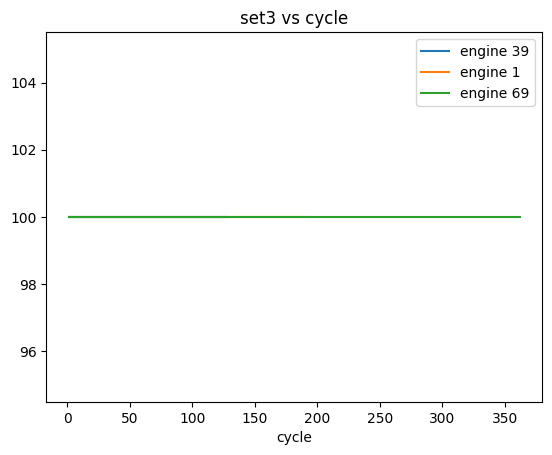

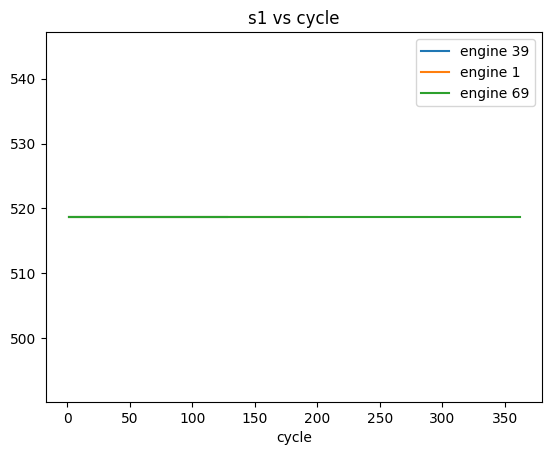

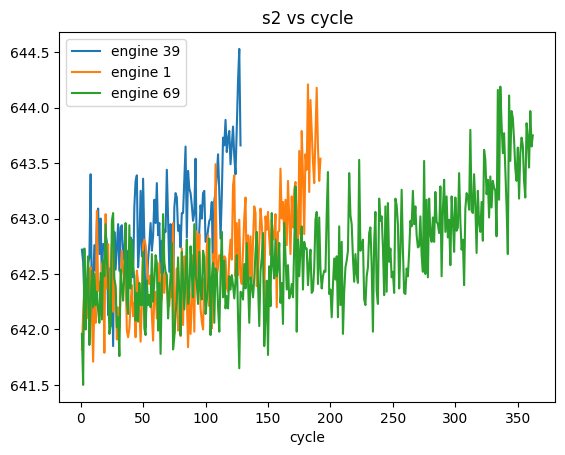

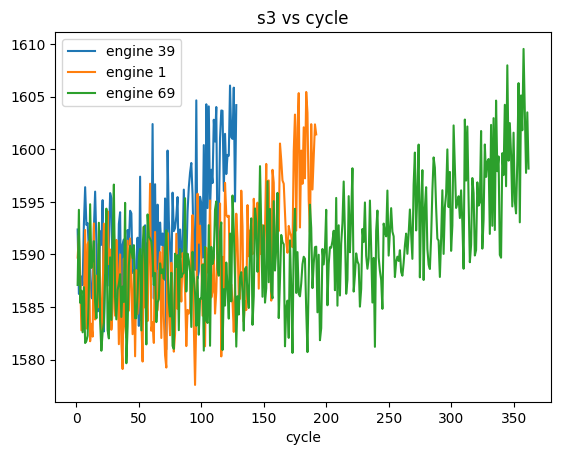

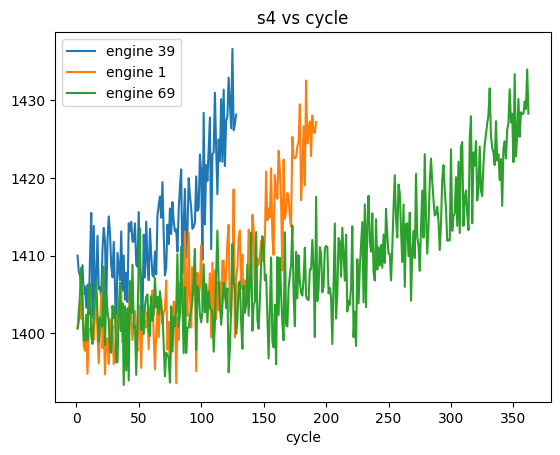

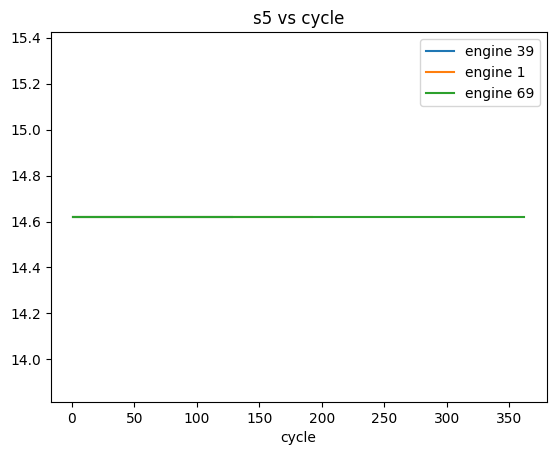

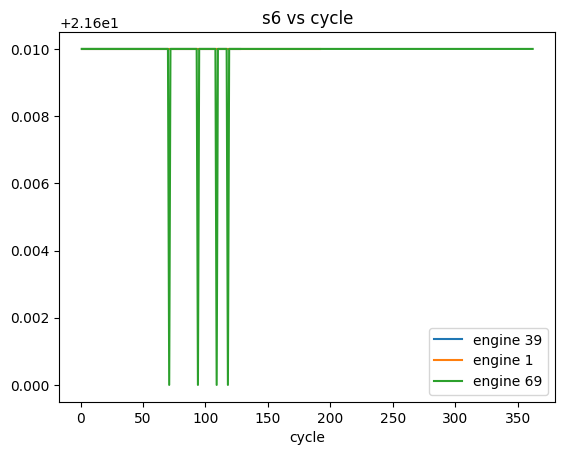

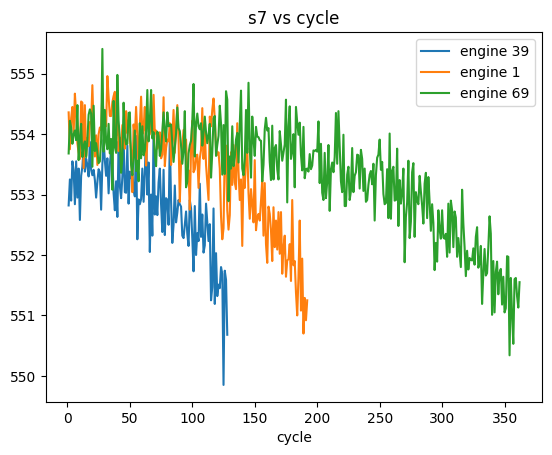

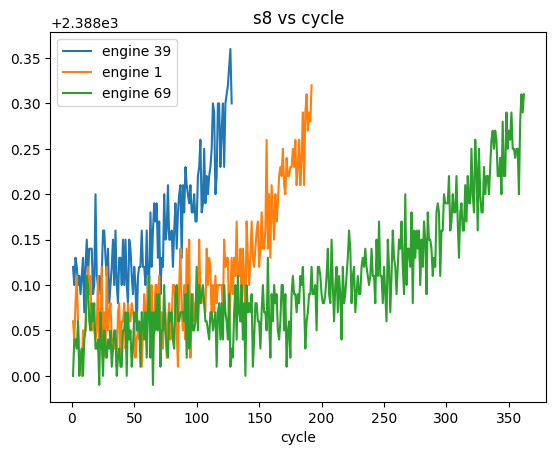

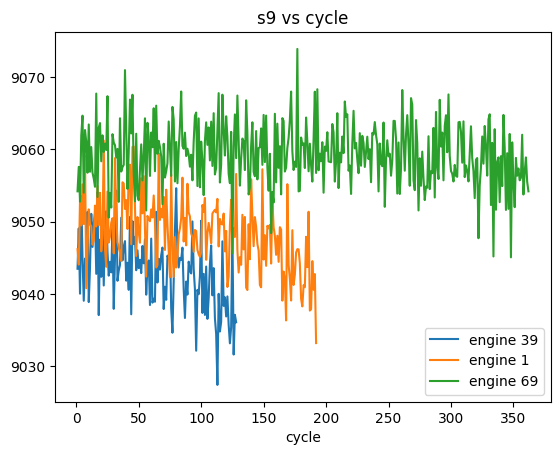

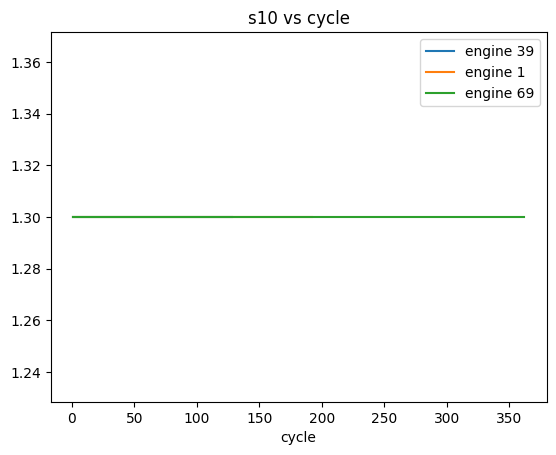

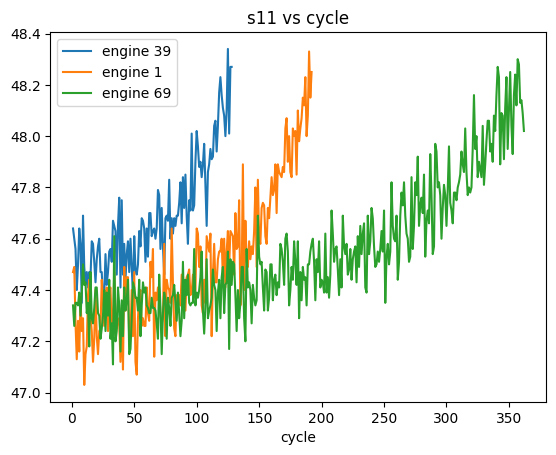

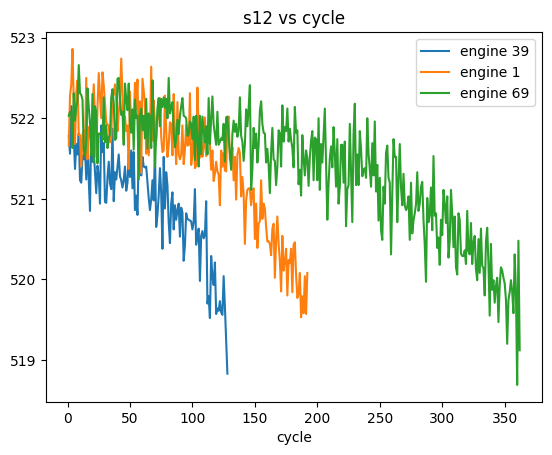

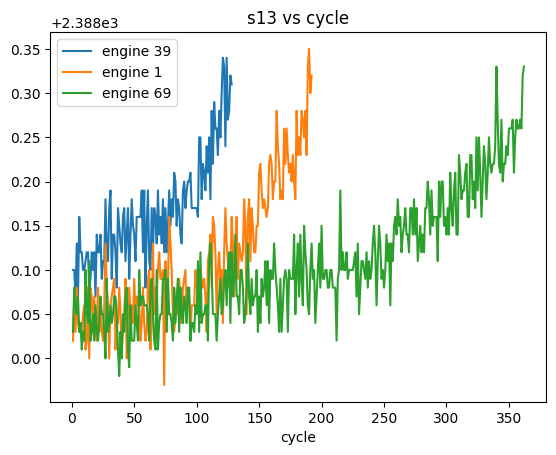

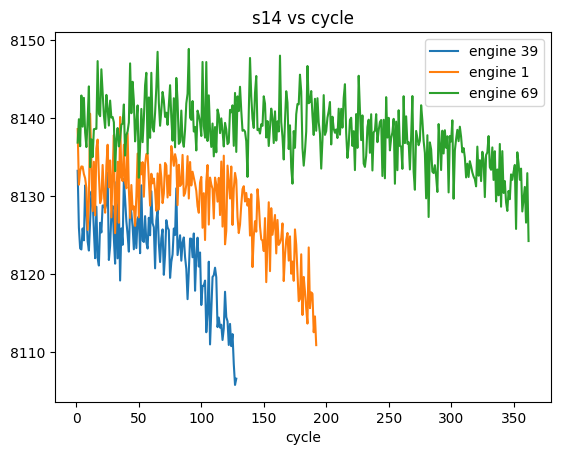

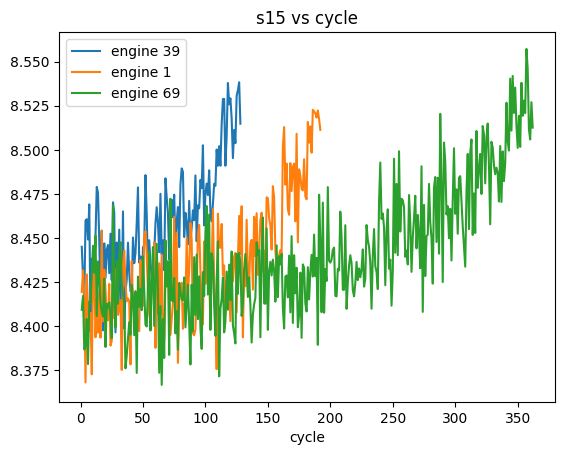

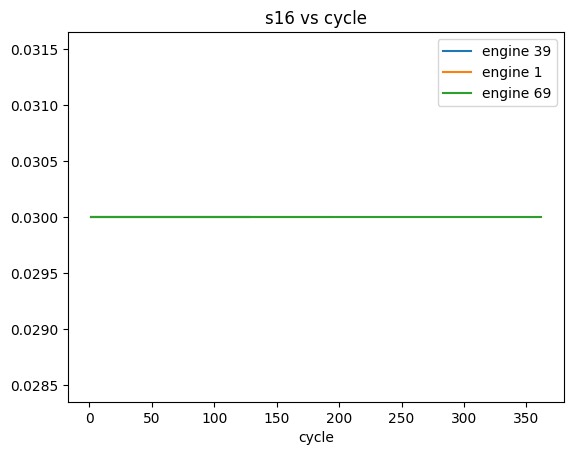

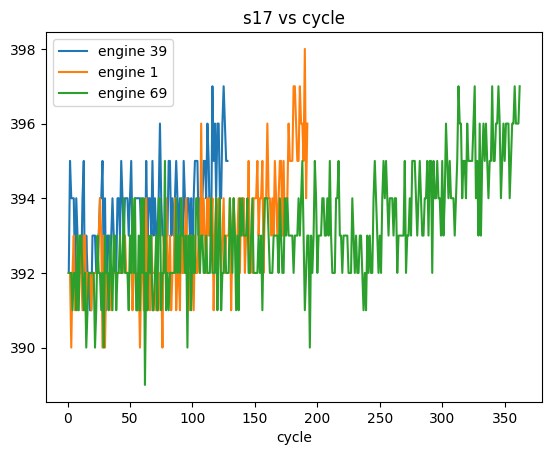

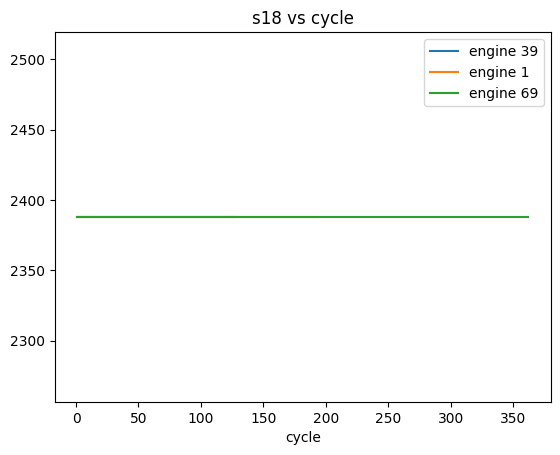

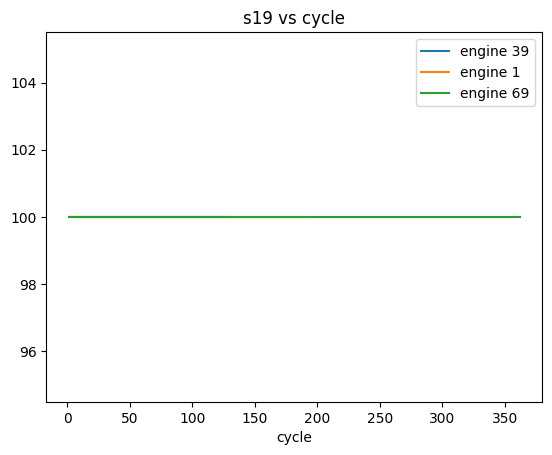

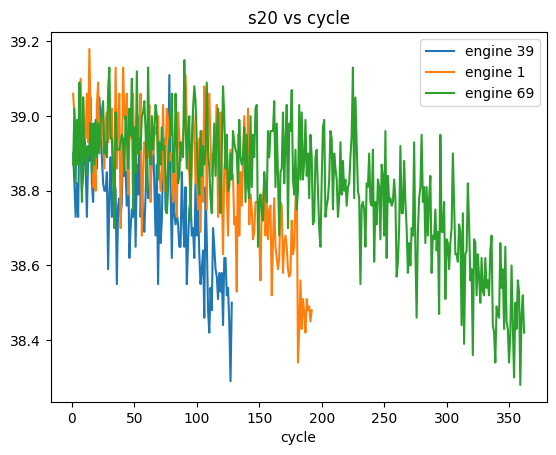

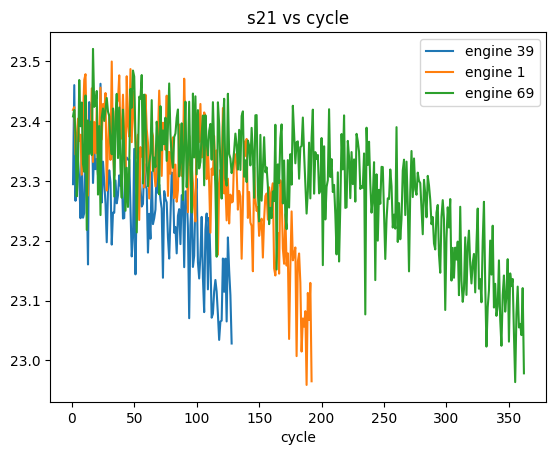

In [19]:
# every setting and sensor against cycle, one chart each
for col in cols[2:]:
    for e in engines:
        one = df[df["unit"] == e]
        plt.plot(one["cycle"], one[col], label=f"engine {e}")
    plt.title(f"{col} vs cycle")
    plt.xlabel("cycle")
    plt.legend()
    plt.show()

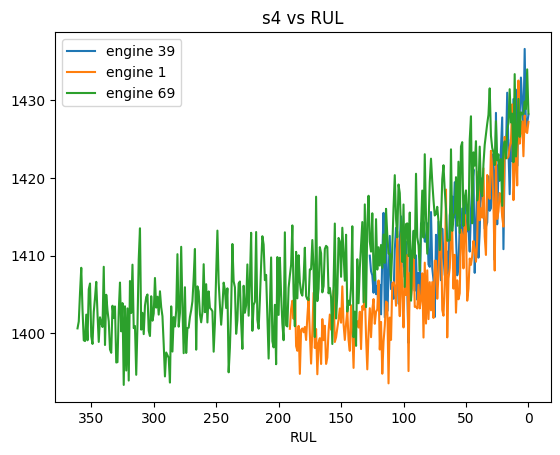

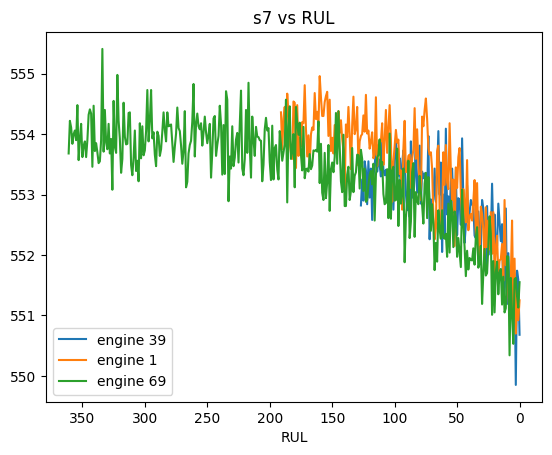

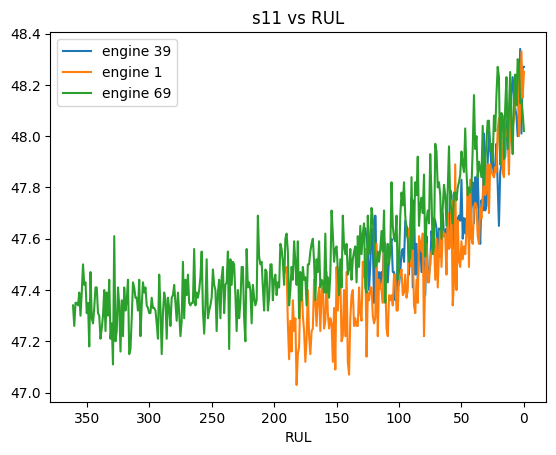

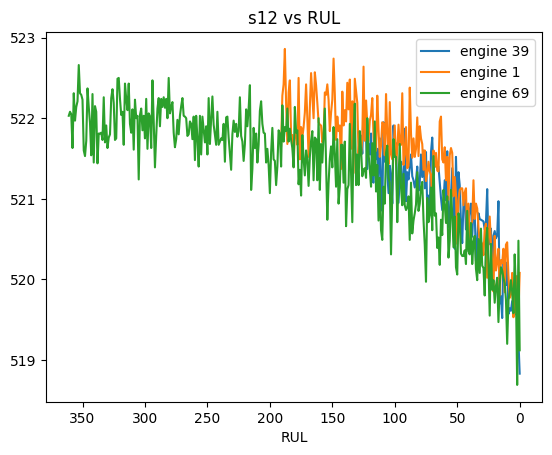

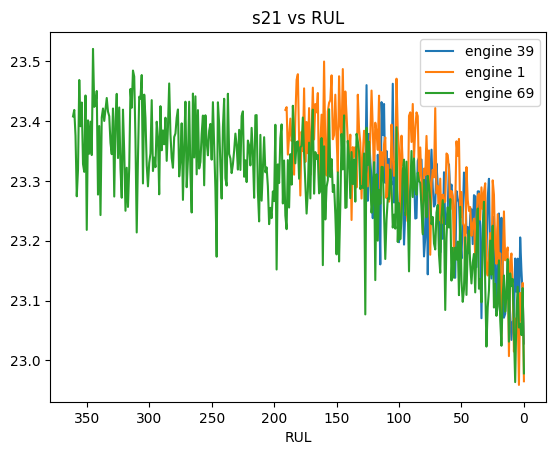

In [20]:
# the same engines against RUL: failure is at the right edge (0)
for col in ["s4", "s7", "s11", "s12", "s21"]:
    for e in engines:
        one = df[df["unit"] == e]
        plt.plot(one["RUL"], one[col], label=f"engine {e}")
    plt.gca().invert_xaxis()
    plt.title(f"{col} vs RUL")
    plt.xlabel("RUL")
    plt.legend()
    plt.show()

In [21]:
# does each sensor move the same way in every engine? (last 10 cycles vs first 10)
first10 = df.groupby("unit").head(10).groupby("unit")[["s4", "s9", "s11","s20"]].mean()
last10 = df.groupby("unit").tail(10).groupby("unit")[["s4", "s9", "s11","s20"]].mean()
change = last10 - first10
pd.DataFrame({"engines rising": (change > 0).sum(), "engines falling": (change < 0).sum()})

,engines rising,engines falling
s4,100,0
s9,70,30
s11,100,0
s20,0,100


## 6. Correlation with RUL
Constant columns give `NaN` or tiny rounding noise (about 1e-15), and may print a divide warning. Both are harmless.

In [22]:
corr_rul = df[cols[2:]].corrwith(df["RUL"]).sort_values()
corr_rul

/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/usr/local/lib/python3.13/dist-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,0
s11,-6.962281e-01
s4,-6.789482e-01
s15,-6.426670e-01
s2,-6.064840e-01
s17,-6.061536e-01
s3,-5.845204e-01
s8,-5.639684e-01
s13,-5.625688e-01
s9,-3.901016e-01
s14,-3.067689e-01


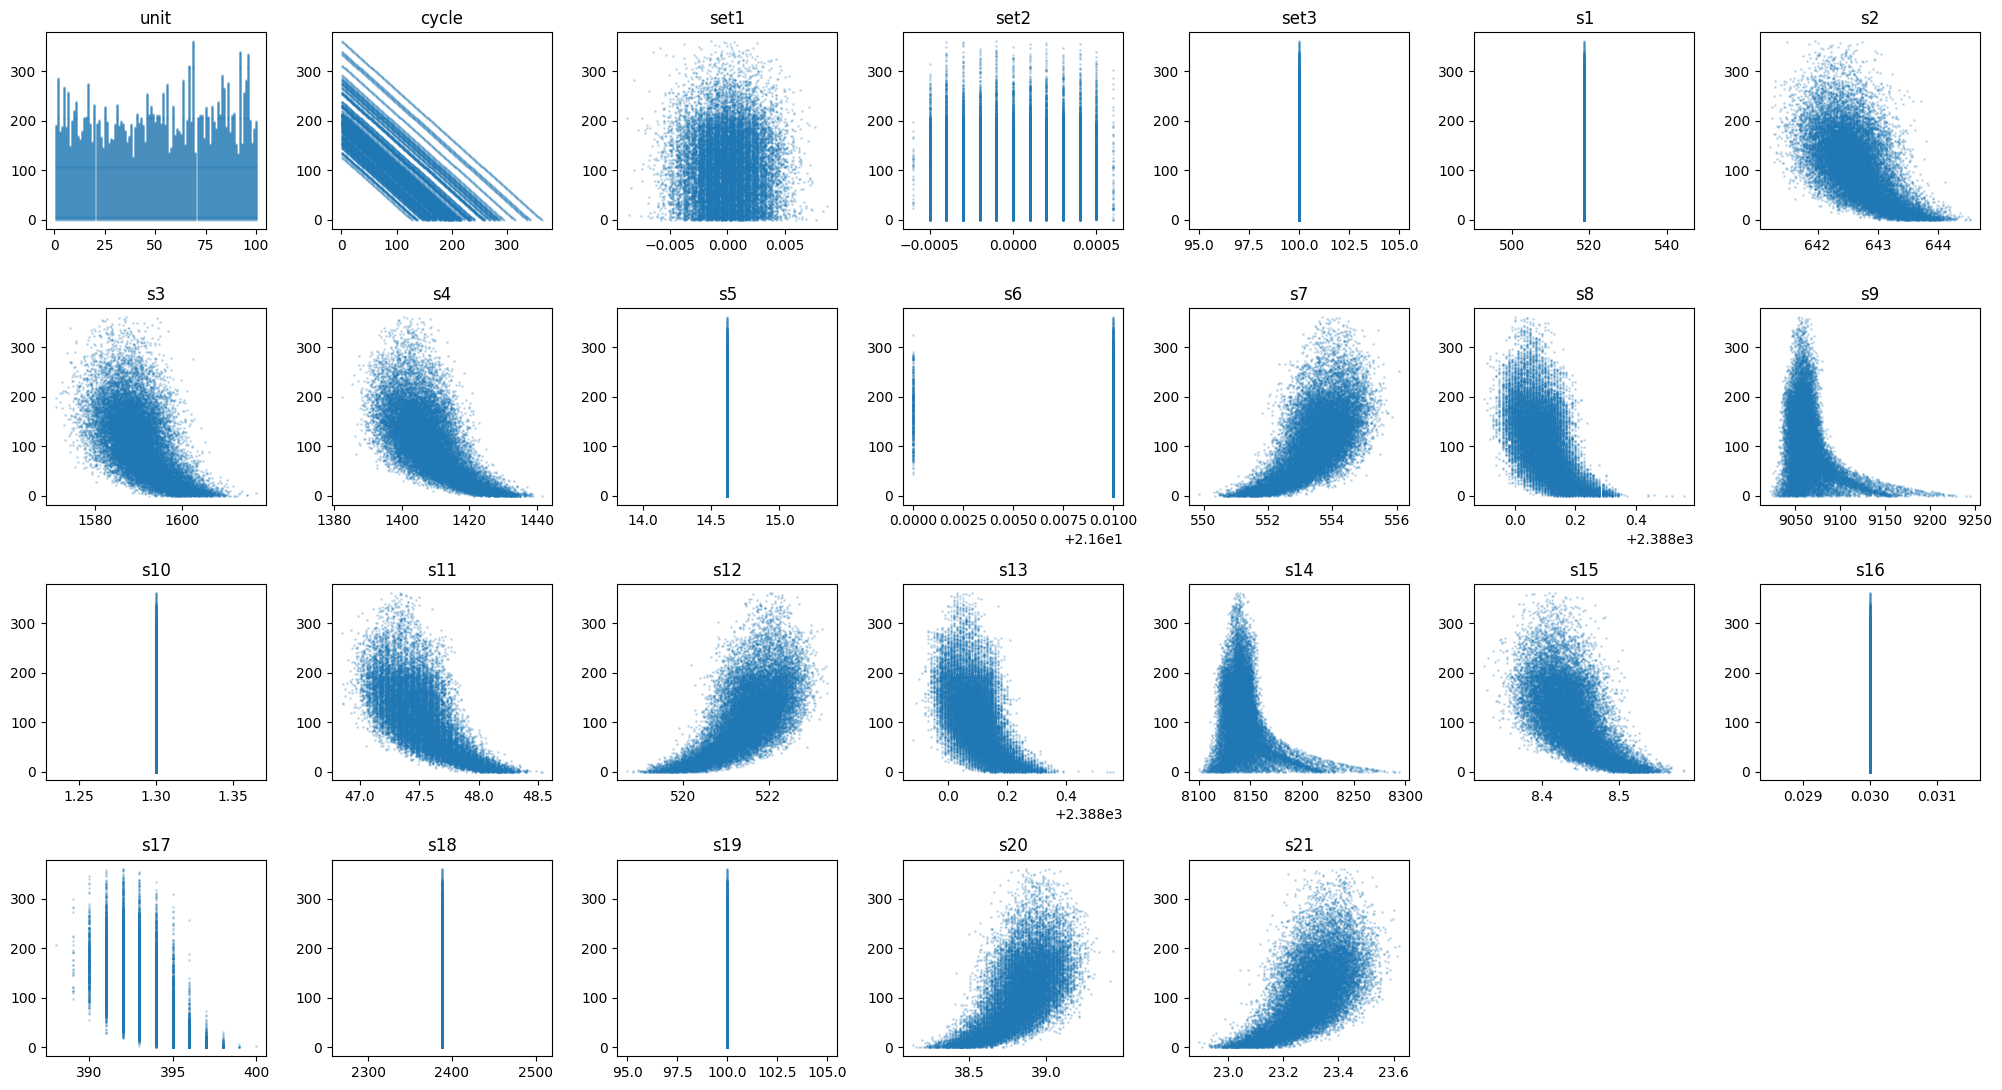

In [23]:
# every column against RUL
fig, axes = plt.subplots(4, 7, figsize=(20, 11))
for ax, col in zip(axes.flat, cols):
    ax.scatter(df[col], df["RUL"], s=1, alpha=0.2)
    ax.set_title(col)
for ax in axes.flat[len(cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 7. Features
The model gets the raw readings of the last 30 cycles of each kept sensor: one column per sensor per cycle. They look **backwards only** and stay **within one engine**.

In [24]:
# the 14 sensors kept in step A2
sensors = ["s2", "s3", "s4", "s7", "s8", "s9", "s11", "s12",
           "s13", "s14", "s15", "s17", "s20", "s21"]

W = 30   # how many past cycles the model sees

def add_lags(d):
    d = d.drop(columns=[c for c in d.columns if "_lag" in c])   # remove old lags if the cell is re-run
    d = d.sort_values(["unit", "cycle"]).reset_index(drop=True)
    g = d.groupby("unit")
    parts = []
    for c in sensors:
        lags = pd.DataFrame({f"{c}_lag{l}": g[c].shift(l) for l in range(W)})  # the reading l cycles ago, same engine
        parts.append(lags.bfill(axis=1).ffill(axis=1))                        # early cycles: repeat the oldest reading
    return pd.concat([d] + parts, axis=1)                                      # attach all columns at once

df = add_lags(df)
df[df["unit"] == 1][["cycle", "s11", "s11_lag0", "s11_lag1", "s11_lag2"]].head(3)

,cycle,s11,s11_lag0,s11_lag1,s11_lag2
0,1,47.47,47.47,47.47,47.47
1,2,47.49,47.49,47.47,47.47
2,3,47.27,47.27,47.49,47.47


## 8. Feature decisions

In [25]:
# never change (nunique = 1 in train and test)
constant = ["set3", "s1", "s5", "s10", "s16", "s18", "s19"]

# vary only as noise: FD001 has one flight condition, correlation with RUL about 0
noise = ["set1", "set2"]

# only 2 values, weak early-life pattern
maybe = ["s6"]

# never inputs: ID, the answers (targets), and the failure point (leakage)
never = ["unit", "RUL", "cycles_left_capped", "failure_cycle",
         "RUL_cap100", "RUL_cap150"]

lag_cols = [f"{c}_lag{l}" for c in sensors for l in range(W)]
seq_features = lag_cols + ["cycle"]

# safety checks: the answer must never be an input
for col in constant + noise + maybe + never:
    assert col not in seq_features
assert len(seq_features) == 421

## 9. Cross-validation by engine
5 rounds; each engine is in validation exactly once. Scores are mean ± spread across rounds, on rows with RUL ≤ 150, against the **true** RUL (never the capped one).

In [26]:
def cv_score(make_model, cols, target="cycles_left_capped", splitter=GroupKFold(n_splits=5)):
    scores = []
    for tr_idx, va_idx in splitter.split(df, groups=df["unit"]):
        tr, va = df.iloc[tr_idx], df.iloc[va_idx]
        model = make_model().fit(tr[cols], tr[target])
        pred = model.predict(va[cols])
        near = (va["RUL"] <= 150).values
        scores.append(root_mean_squared_error(va["RUL"][near], pred[near]))
    return np.mean(scores), np.std(scores)

In [27]:
mlp = lambda: make_pipeline(StandardScaler(),
                            MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                         max_iter=300, random_state=0))
baseline = lambda: DummyRegressor(strategy="mean")   # always predicts the average training RUL

cv_base = cv_score(baseline, seq_features)
cv_mlp = cv_score(mlp, seq_features)
print("baseline (always the average) %.1f ± %.1f" % cv_base)
print("MLP, last 30 cycles           %.1f ± %.1f" % cv_mlp)

baseline (always the average) 45.1 ± 0.0
MLP, last 30 cycles           16.1 ± 0.3


In [28]:
# which cap works best? (no cap = train on the true RUL)
print("no cap ", "%.1f ± %.1f" % cv_score(mlp, seq_features, target="RUL"))
for cap in [100, 150]:
    df[f"RUL_cap{cap}"] = df["RUL"].clip(upper=cap)
    print(f"cap {cap}", "%.1f ± %.1f" % cv_score(mlp, seq_features, target=f"RUL_cap{cap}"))
print("cap 125", "%.1f ± %.1f" % cv_mlp)

no cap  27.2 ± 2.7
cap 100 20.4 ± 0.5
cap 150 17.7 ± 1.0
cap 125 16.1 ± 0.3


## 10. Other models compared
How the MLP was chosen. All scored with the same cross-validation. The tree models also get summary features: each sensor's average and spread over the last 10 cycles.

In [29]:
for c in sensors:
    df[f"{c}_mean10"] = df.groupby("unit")[c].transform(lambda x: x.rolling(10, min_periods=1).mean())
    df[f"{c}_std10"] = df.groupby("unit")[c].transform(lambda x: x.rolling(10, min_periods=2).std()).fillna(0)
summary = ["cycle"] + sensors + [f"{c}_mean10" for c in sensors] + [f"{c}_std10" for c in sensors]

lgbm = lambda: lgb.LGBMRegressor(n_estimators=400, learning_rate=0.02, num_leaves=15,
                                 min_child_samples=50, random_state=0, verbose=-1)
forest = lambda: RandomForestRegressor(n_estimators=100, min_samples_leaf=5, random_state=0, n_jobs=-1)
xgbm = lambda: xgb.XGBRegressor(n_estimators=400, learning_rate=0.02, max_depth=4, min_child_weight=50,
                                subsample=0.8, colsample_bytree=0.8, random_state=0)

compare = {"baseline (always the average)": cv_base}
for name, make, cols_ in [
    ("linear, 14 sensors", LinearRegression, sensors),
    ("lgbm, 14 sensors", lgbm, sensors),
    ("forest, 43 summary features", forest, summary),
    ("xgboost, 43 summary features", xgbm, summary),
    ("lgbm, 43 summary features", lgbm, summary),
    ("lgbm, 43 summary + s6", lgbm, summary + ["s6"]),
    ("lgbm, 43 summary + set1, set2", lgbm, summary + ["set1", "set2"]),
    ("lgbm, last 30 cycles", lgbm, seq_features),
]:
    compare[name] = cv_score(make, cols_)
compare["MLP, last 30 cycles"] = cv_mlp

# leakage check: rows split at random instead of by engine
compare["forest, summary, RANDOM ROWS (fake)"] = cv_score(forest, summary, splitter=KFold(n_splits=5, shuffle=True, random_state=0))
compare["MLP, last 30, RANDOM ROWS (fake)"] = cv_score(mlp, seq_features, splitter=KFold(n_splits=5, shuffle=True, random_state=0))

pd.DataFrame(compare, index=["RMSE", "±"]).T.round(1)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:86: UserWarning: The groups parameter is ignored by KFold
  warnings.warn(


,RMSE,±
baseline (always the average),45.1,0.0
"linear, 14 sensors",24.3,0.8
"lgbm, 14 sensors",22.1,1.7
"forest, 43 summary features",20.2,1.3
"xgboost, 43 summary features",19.8,1.1
"lgbm, 43 summary features",19.8,1.2
"lgbm, 43 summary + s6",19.8,1.2
"lgbm, 43 summary + set1, set2",19.8,1.2
"lgbm, last 30 cycles",17.9,0.6
"MLP, last 30 cycles",16.1,0.3


**Decision:** the MLP on the last 30 cycles beats every other model (16.1 vs 17.9 for the next best, and 19.8 to 20.2 for the tree models on summary features). Settings and s6 are left out: adding them to LightGBM's summary features changed nothing (19.8 in all cases).

**Random rows:** splitting rows at random makes the forest look far better than it is (13.0 vs 20.2), because it memorises near-identical neighbouring rows from engines it has seen. The MLP barely changes (15.6 vs 16.1). The leak is real; how much it inflates the score depends on the model.

## 11. Final evaluation on test and analysis
Train the MLP on all 100 training engines and score it at each test engine's last cycle. A neural network starts from random weights, so it is trained with 3 seeds and the range is reported; seed 0 is the final model.

In [30]:
def nasa_score(d):
    # error = prediction - truth; late (positive) errors are punished harder
    return np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1))

test_seq = add_lags(test)
last_seq = test_seq.groupby("unit").tail(1).merge(rul, on="unit")

In [31]:
models = {}
for seed in [0, 1, 2]:
    models[seed] = make_pipeline(StandardScaler(),
                                 MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True,
                                              max_iter=300, random_state=seed))
    models[seed].fit(df[seq_features], df["cycles_left_capped"])
    p = models[seed].predict(last_seq[seq_features])
    print(seed, "RMSE", round(root_mean_squared_error(last_seq["RUL"], p), 2),
          "NASA", round(nasa_score(p - last_seq["RUL"])))

final_mlp = models[0]

0 RMSE 14.94 NASA 337
1 RMSE 15.48 NASA 384
2 RMSE 14.8 NASA 320


In [32]:
results = last_seq[["unit", "cycle", "RUL"]].copy()
results["pred"] = final_mlp.predict(last_seq[seq_features])
results["error"] = results["pred"] - results["RUL"]

print("RMSE:", round(root_mean_squared_error(results["RUL"], results["pred"]), 2))
print("NASA score:", round(nasa_score(results["error"])))
print("MAE:", round(mean_absolute_error(results["RUL"], results["pred"]), 1))
print("Mean error (bias):", round(results["error"].mean(), 1))
print("Within ±15 cycles:", (results["error"].abs() <= 15).sum(), "of 100")
print("Late by more than 15:", (results["error"] > 15).sum())

RMSE: 14.94
NASA score: 337
MAE: 11.7
Mean error (bias): -0.3
Within ±15 cycles: 70 of 100
Late by more than 15: 16


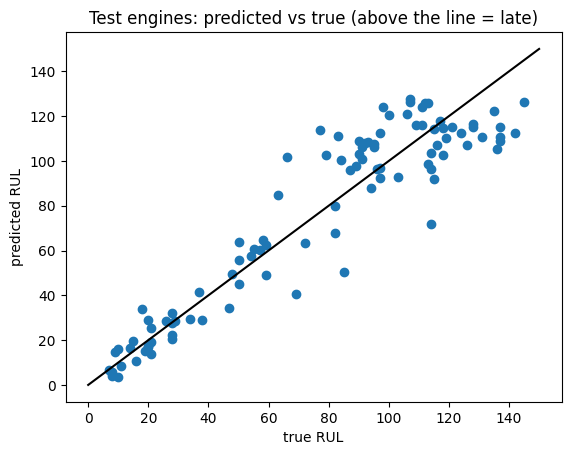

,unit,cycle,RUL,pred,error
44,45,152,114,71.752475,-42.247525
66,67,71,77,113.900265,36.900265
26,27,140,66,101.734608,35.734608
92,93,244,85,50.404209,-34.595791
88,89,177,136,105.270716,-30.729284


In [33]:
plt.scatter(results["RUL"], results["pred"])
plt.plot([0, 150], [0, 150], color="black")
plt.xlabel("true RUL")
plt.ylabel("predicted RUL")
plt.title("Test engines: predicted vs true (above the line = late)")
plt.show()

results.loc[results["error"].abs().nlargest(5).index]

In [34]:
# where and in which direction is the model wrong?
results["band"] = pd.cut(results["RUL"], [0, 25, 50, 75, 100, 125, 150])
results.groupby("band", observed=True).apply(lambda g: pd.Series({
    "engines": len(g),
    "RMSE": root_mean_squared_error(g["RUL"], g["pred"]),
    "mean error": g["error"].mean(),
}), include_groups=False).round(1)

,engines,RMSE,mean error
band,,,
"(0, 25]",19.0,5.9,0.3
"(25, 50]",14.0,6.8,-0.9
"(50, 75]",10.0,16.9,3.4
"(75, 100]",24.0,17.8,9.8
"(100, 125]",22.0,15.4,-2.9
"(125, 150]",11.0,22.1,-21.1


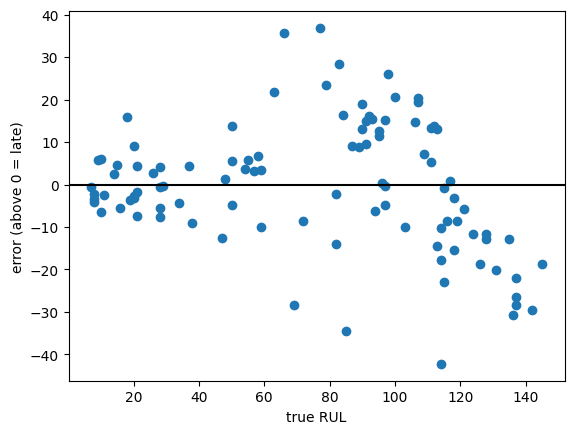

In [35]:
plt.scatter(results["RUL"], results["error"])
plt.axhline(0, color="black")
plt.xlabel("true RUL")
plt.ylabel("error (above 0 = late)")
plt.show()

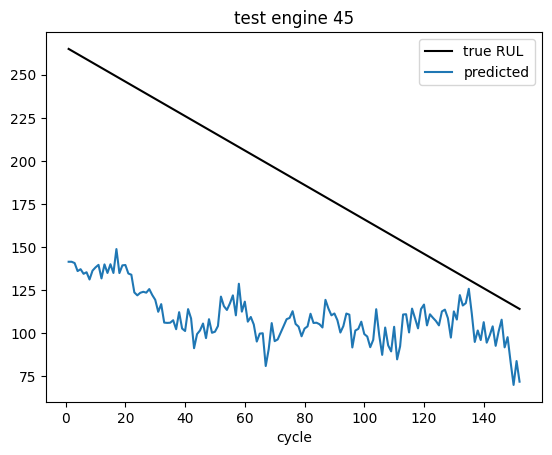

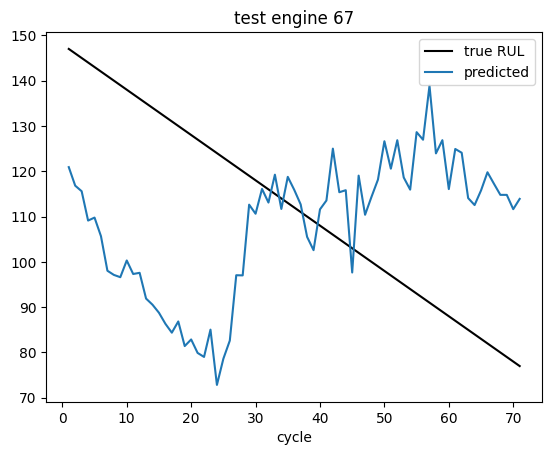

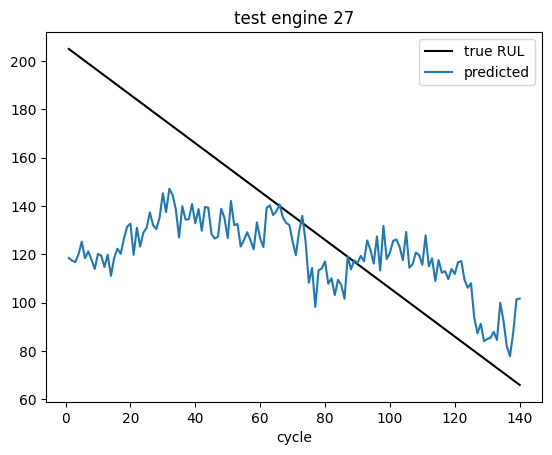

In [36]:
# predictions over each of the 3 worst engines' test history, against the true RUL
test_all = test_seq.copy()
test_all["pred"] = final_mlp.predict(test_all[seq_features])
test_all = test_all.merge(rul.rename(columns={"RUL": "rul_at_cut"}), on="unit")
test_all["true_RUL"] = test_all["rul_at_cut"] + test_all.groupby("unit")["cycle"].transform("max") - test_all["cycle"]

for e in results.loc[results["error"].abs().nlargest(3).index, "unit"]:
    one = test_all[test_all["unit"] == e]
    plt.plot(one["cycle"], one["true_RUL"], label="true RUL", color="black")
    plt.plot(one["cycle"], one["pred"], label="predicted")
    plt.title(f"test engine {e}")
    plt.xlabel("cycle")
    plt.legend()
    plt.show()

## 12. Results

### Model (5-fold cross-validation by engine, RMSE in cycles, rows with RUL ≤ 150)
| | RMSE |
|---|---|
| Baseline: always the average | 45.1 |
| **MLP, last 30 cycles, cap 125** | **16.1 ± 0.3** |
| Same MLP without a cap | 27.2 ± 2.7 |
| Cap 100 / cap 150 | 20.4 / 17.7 |
| Best other model (LightGBM, last 30 cycles) | 17.9 ± 0.6 |
| Tree models on summary features | 19.8 to 20.2 |

### Test (NASA's 100 test engines, last cycle of each)
| Metric | Value |
|---|---|
| RMSE | **14.9** (14.8 to 15.5 over 3 seeds) |
| NASA score | **337** (320 to 384 over 3 seeds) |
| MAE | 11.7 |
| Mean error (bias) | −0.3 |
| Within ±15 cycles | 70 of 100 |
| Late by more than 15 | 16 of 100 |

The model was chosen by cross-validation, not by its test score, and the seed range is reported, not the best seed. For transparency: before the MLP was tried, LightGBM on the summary features had also been scored on the test set (RMSE 19.0, NASA 765), so the test set was used twice.

### Where and in which direction the model is wrong
| True RUL | Engines | RMSE | Mean error |
|---|---|---|---|
| 0 to 25 | 19 | 5.9 | +0.3 |
| 25 to 50 | 14 | 6.8 | −0.9 |
| 50 to 75 | 10 | 16.9 | +3.4 |
| 75 to 100 | 24 | 17.8 | +9.8 (late) |
| 100 to 125 | 22 | 15.4 | −2.9 |
| 125 to 150 | 11 | 22.1 | −21.1 (early) |

- **Near failure the model is accurate and unbiased:** RMSE 5.9 and 6.8 below 50 cycles left, bias close to 0.
- **The late errors are further from failure:** at 75 to 100 cycles left the model is late by about 10 cycles on average. That is less dangerous, because the prediction is updated every cycle and has time to correct before failure.
- At 125 to 150 it is early by about 21: the cap. Early is the safe direction.
- Worst misses: engine 45 (true 114, predicted 72, early), engines 67 and 27 (true 77 and 66, predicted 114 and 102, about 36 late), engines 93 and 89 (early).

### What this means for Part B
- The alert threshold must be chosen by cost: a failure in service versus early maintenance, not by RMSE.
- The model's late errors are mid-life (75 to 100 cycles left), so the threshold has to be judged on how quickly predictions correct as engines approach failure.

## 13. Observations from exploration

### The data
- Train: 100 engines, 20,631 rows. Every engine runs until failure. Lives range from 128 to 362 cycles (median 199, mean 206).
- Test: 100 different engines, 13,096 rows. NASA cut each one before failure: observed for 31 to 303 cycles (median 133.5), cut 7 to 145 cycles before failure (median 86).

### Data quality
- No duplicate rows, no missing values.
- Every engine starts at cycle 1 and has no gaps (row count = last cycle).

### How the files fit together
- The RUL file has no engine column; values match test engines by position. pandas counts rows from 0, so `unit = index + 1`.
- Check: `nasa_cut_cycle` + `RUL` = `failure_cycle`. Test engines then have mean 206.5 and median 199, almost identical to train (206.3, 199). The match is correct.
- Medians can't be added together (133.5 + 86 ≠ 199). Combine per engine first, then summarise.

### Columns dropped
- Constant (1 distinct value in train and test): set3, s1, s5, s10, s16, s18, s19. Their correlations with RUL are NaN or rounding noise (about 1e-15).
- Noise: set1, set2. FD001 has one operating condition; correlation with RUL about 0. Cross-validation: no effect.
- s6: only two values (21.60, 21.61); the 21.60 dips occur mostly early in life. Correlation -0.13. Cross-validation: no effect.
- Never features: unit (ID), RUL and cycles_left_capped (the answers), failure_cycle (leakage: it is the failure point itself).
- Kept: 14 sensors (s2, s3, s4, s7, s8, s9, s11, s12, s13, s14, s15, s17, s20, s21). Model inputs: their last 30 readings + cycle = 421.

### How the sensors behave
- Sensors are flat and noisy for most of an engine's life, then drift near failure.
- Rise with wear (negative correlation with RUL): s11 (-0.70), s4 (-0.68), s15 (-0.64), s2 (-0.61), s17 (-0.61).
- Fall with wear (positive correlation): s12 (+0.67), s7 (+0.66), s21 (+0.64), s20 (+0.63).
- s4 and s11 rise in all 100 engines and s20 falls in all 100 (last 10 cycles vs first 10). s9 rises in 70 and falls in 30, so it is a less reliable signal (correlation -0.39).
- s9 and s14 are near-duplicates (correlation 0.96): two versions of core speed.
- Engines start at slightly different levels (initial wear and manufacturing variation) but end at a similar level, e.g. s21 about 23.0 to 23.1.
- Plotted against RUL instead of cycle, different engines follow almost the same curve near failure: sensors depend on distance to failure, not age.
- s17 is recorded in whole numbers, so single readings hide small changes.
- Sensor meanings come from Table 2 of Saxena et al. (2008), assuming the columns follow the table's order (s1 = 518.67 = sea-level temperature fits).

### Why the later steps were done this way
- Cap RUL: far from failure the sensors are flat, so RUL 150 looks the same as RUL 250. Cost: no long-range prediction above 125.
- Last 30 cycles as inputs: single readings are noisy; the recent history shows the trend and its shape.
- Split by engine: rows of one engine are near-duplicates (random rows made a forest look like 13.0 instead of 20.2).
- Test sensors vary less than train (e.g. s4 std 6.7 vs 9.0) because test engines never reach end-of-life readings. Relevant for drift checks later.

## 14. Summary in my own words

**The problem.** Airlines want to service engines before they fail, but not too early. I built a model that reads an engine's sensor history and predicts its remaining useful life (RUL): how many cycles it has left.

**The data.** NASA's C-MAPSS FD001: simulated jet engines, one row per cycle, with 3 operating settings and 21 sensors. The 100 training engines run until they fail, so RUL on every row is failure cycle minus current cycle. The 100 test engines are cut off before failure, and NASA gives their true RUL separately. I checked that the files fit together: cut-off cycle + RUL gives test lifetimes matching the training ones (median 199 in both).

**Exploration and feature decisions.** Seven columns never change, so I dropped them. The two operating settings are noise in FD001, and s6 only takes two values; adding them to a model changed nothing. That left 14 sensors. Most are flat for much of an engine's life and drift near failure: s4 and s11 rise in every engine and s20 falls in every engine, while s9 rises in only 70 of 100. Plotted against RUL instead of age, different engines follow almost the same curve, which is the pattern the model learns.

**The model.** For each cycle, the model gets the raw readings of the last 30 cycles of the 14 sensors, plus the cycle number: 421 inputs. It sees how the sensors are moving, not just where they are. It is a small neural network (MLP, two layers of 64 and 32).

**Capping RUL at 125.** Far from failure the sensors look the same whether an engine has 150 or 300 cycles left, so I capped the label at 125. I always scored against the true RUL, so the cap can't hide errors. Without the cap the same model scores 27.2; with cap 125 it scores 16.1, better than caps of 100 (20.4) and 150 (17.7). The cost: no prediction above 125.

**Evaluation.** 5-fold cross-validation, split by engine: rows from the same engine are nearly identical from one cycle to the next, so a random row split leaks. It made a forest look like 13.0 instead of 20.2.

**Model choice.** Always guessing the average scores 45.1. The MLP scores 16.1 ± 0.3. Linear regression, random forest, XGBoost and LightGBM all did worse; the best of them was LightGBM on the same 30-cycle inputs (17.9). The input format mattered more than the model type.

**Test result.** On NASA's 100 test engines: RMSE 14.9 and NASA score 337 (14.8 to 15.5 and 320 to 384 over three random seeds), MAE 11.7, and 70 of 100 engines within 15 cycles. The test set was also used once earlier, for LightGBM (RMSE 19.0), before the MLP was tried.

**What the analysis showed.** One RMSE hides the important part. Near failure the model is accurate (RMSE about 6 below 50 cycles left, no bias). Its late errors are further from failure (about 10 cycles late at 75 to 100 left), where there is still time to correct. The largest errors are early ones above 125 cycles left, caused by the cap, which is safe.

**Limits and next steps.** The data is simulated, with one operating condition and one fault type, and the test set has only 100 engines. Next I'll turn predictions into a maintenance decision: an alert threshold chosen by the cost of failures versus early servicing. Then the production parts: scripts, tests, an API and drift monitoring.

## 15. Alert decision

In [38]:
df["oof_pred"] = np.nan
for tr_idx, va_idx in GroupKFold(n_splits=5).split(df, groups=df["unit"]):
    m = mlp().fit(df.iloc[tr_idx][seq_features], df.iloc[tr_idx]["cycles_left_capped"])
    df.loc[df.index[va_idx], "oof_pred"] = m.predict(df.iloc[va_idx][seq_features])

In [39]:
LEAD = 10   # cycles needed to arrange maintenance

def replay(k, lead=LEAD):
    rows = []
    for unit, e in df.groupby("unit"):
        hit = e[e["oof_pred"] <= k]                    # cycles where the alert would fire
        if hit.empty or hit.iloc[0]["RUL"] < lead:     # never fired, or too late: failure
            rows.append((unit, True, 0))
        else:
            rows.append((unit, False, int(hit.iloc[0]["RUL"]) - lead))
    return pd.DataFrame(rows, columns=["unit", "failed", "wasted"])

def cost(k, c_fail=100, c_cycle=1):
    r = replay(k)
    return r["failed"].sum(), r["wasted"].sum(), r["failed"].sum() * c_fail + r["wasted"].sum() * c_cycle

ks = [10, 15, 20, 25, 30, 35, 40, 50]
pd.DataFrame([(k, *cost(k)) for k in ks], columns=["k", "failures", "wasted cycles", "cost"])

,k,failures,wasted cycles,cost
0,10,31,194,3294
1,15,6,712,1312
2,20,0,1265,1265
3,25,0,1845,1845
4,30,0,2379,2379
5,35,0,2917,2917
6,40,0,3440,3440
7,50,0,4278,4278


In [40]:
for c_fail in [50, 100, 500, 1000]:
    best = min(ks, key=lambda k: cost(k, c_fail=c_fail)[2])
    print("failure cost", c_fail, "-> best k", best, cost(best, c_fail=c_fail))

failure cost 50 -> best k 15 (np.int64(6), np.int64(712), np.int64(1012))
failure cost 100 -> best k 20 (np.int64(0), np.int64(1265), np.int64(1265))
failure cost 500 -> best k 20 (np.int64(0), np.int64(1265), np.int64(1265))
failure cost 1000 -> best k 20 (np.int64(0), np.int64(1265), np.int64(1265))
